# Phase 6 : Arbre de régression et SVR (Bike Sharing)

Deux algorithmes supplémentaires, en complément de Ridge et Random Forest déjà réalisés.

**Protocole (énoncé du Mini-Projet 04)**
- Split **chronologique** : 80 % premières lignes = train, 20 % dernières = test (`shuffle=False`)
- Réglage par `GridSearchCV` + `TimeSeriesSplit` **uniquement sur le train**
- Une seule évaluation sur le test : MAE, RMSE, R² (+ RMSLE)
- Ridge et Random Forest sont ré-entraînés dans **les mêmes conditions** pour comparer à armes égales

> ⚠️ Dans `modelisation_ridge_rf.ipynb`, le découpage utilise `train_test_split(..., shuffle=True)` : le test mélange des heures du train (fuite temporelle), ce qui gonfle les scores (RF : R² = 0,945). Ici, le test est réellement le futur (août à décembre 2012). À corriger aussi dans ce notebook-là.

In [ ]:
import time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressork;
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"]=110
DATA_PATH="../bike_sharing_final.csv"; TARGET="cnt"; SEED=42
FIG_DIR=Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def save_show(name): plt.tight_layout(); plt.savefig(FIG_DIR/f"{name}.png",bbox_inches="tight"); plt.show()

## 1. Chargement et split chronologique 80 / 20

In [2]:
df=pd.read_csv(DATA_PATH)
assert df.isna().sum().sum()==0
X=df.drop(columns=TARGET); y=df[TARGET]
n=int(len(df)*0.8)
X_train,X_test,y_train,y_test=X.iloc[:n],X.iloc[n:],y.iloc[:n],y.iloc[n:]
mois=lambda d:f"{2011+int(d['yr'])}-{int(d['mnth']):02d}"
print(f"Train : {len(X_train):,} lignes | {mois(X_train.iloc[0])} -> {mois(X_train.iloc[-1])} | cnt moyen {y_train.mean():.1f}")
print(f"Test  : {len(X_test):,} lignes | {mois(X_test.iloc[0])} -> {mois(X_test.iloc[-1])} | cnt moyen {y_test.mean():.1f}")

Train : 13,903 lignes | 2011-01 -> 2012-08 | cnt moyen 174.6
Test  : 3,476 lignes | 2012-08 -> 2012-12 | cnt moyen 248.8


## 2. Pipelines et réglage (`TimeSeriesSplit`, train uniquement)

| Modèle | Préparation | Hyperparamètres étudiés |
|---|---|---|
| Arbre de régression | aucune (variables brutes, `hr` conservé) | `max_depth`, `min_samples_leaf` |
| SVR (noyau RBF) | standardisation + one-hot, **cible standardisée** | `C`, `gamma` (`epsilon` fixé) |

Le SVR est sensible à l'échelle : les variables numériques sont standardisées, et la cible `cnt` l'est aussi (via `TransformedTargetRegressor`) pour que `epsilon` et `C` aient un sens stable.

In [3]:
tscv=TimeSeriesSplit(n_splits=4)
def tune(name,est,grid):
    t0=time.time()
    gs=GridSearchCV(est,grid,cv=tscv,scoring="neg_root_mean_squared_error",n_jobs=-1).fit(X_train,y_train)
    print(f"{name:<22} {gs.best_params_} | RMSE CV = {-gs.best_score_:.1f} | {time.time()-t0:.0f} s")
    return gs

gs_dt=tune("Arbre de régression",DecisionTreeRegressor(random_state=SEED),
           {"max_depth":[3,5,7,9,12,15,None],"min_samples_leaf":[1,5,10,20]})

svr_pre=ColumnTransformer([("n",StandardScaler(),["temp","hum","windspeed","hr_sin","hr_cos","mnth","yr"]),
    ("c",OneHotEncoder(handle_unknown="ignore"),["season","weathersit","weekday"]),
    ("b","passthrough",["holiday","workingday"])])
svr_pipe=TransformedTargetRegressor(Pipeline([("prep",svr_pre),("m",SVR(kernel="rbf",epsilon=0.1))]),
                                    transformer=StandardScaler())
gs_svr=tune("SVR (RBF)",svr_pipe,{"regressor__m__C":[1,3,10],"regressor__m__gamma":[0.05,0.1,0.3]})

Arbre de régression    {'max_depth': 12, 'min_samples_leaf': 5} | RMSE CV = 89.4 | 15 s
SVR (RBF)              {'regressor__m__C': 3, 'regressor__m__gamma': 0.05} | RMSE CV = 112.7 | 90 s


### Références (mêmes conditions chronologiques)

In [4]:
ridge=Pipeline([("prep",svr_pre),("model",Ridge(alpha=1.0))]).fit(X_train,y_train)
rf=RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=SEED,n_jobs=-1).fit(X_train,y_train)
models={"Arbre de régression":gs_dt.best_estimator_,"SVR (RBF)":gs_svr.best_estimator_,
        "Random Forest (réf.)":rf,"Ridge (réf.)":ridge}
preds={k:m.predict(X_test) for k,m in models.items()}

## 3. Évaluation unique sur le test chronologique

In [5]:
def evaluate(yt,yp):
    return {"MAE":mean_absolute_error(yt,yp),"RMSE":float(np.sqrt(mean_squared_error(yt,yp))),"R²":r2_score(yt,yp),
            "RMSLE":float(np.sqrt(mean_squared_error(np.log1p(yt),np.log1p(np.clip(yp,0,None)))))}
metrics=pd.DataFrame({k:evaluate(y_test,p) for k,p in preds.items()}).T
metrics_train=pd.DataFrame({k:evaluate(y_train,m.predict(X_train)) for k,m in models.items()}).T
display(metrics.round(3))
print("Ratio RMSE test / train :"); print((metrics["RMSE"]/metrics_train["RMSE"]).round(2).to_string())

,MAE,RMSE,R²,RMSLE
Arbre de régression,52.800,81.244,0.864,0.449
SVR (RBF),70.004,114.264,0.731,0.711
Random Forest (réf.),44.944,69.417,0.901,0.400
Ridge (réf.),123.192,165.336,0.438,1.155


Ratio RMSE test / train :
Arbre de régression     2.10
SVR (RBF)               1.61
Random Forest (réf.)    3.35
Ridge (réf.)            1.41


## 4. Visualisations

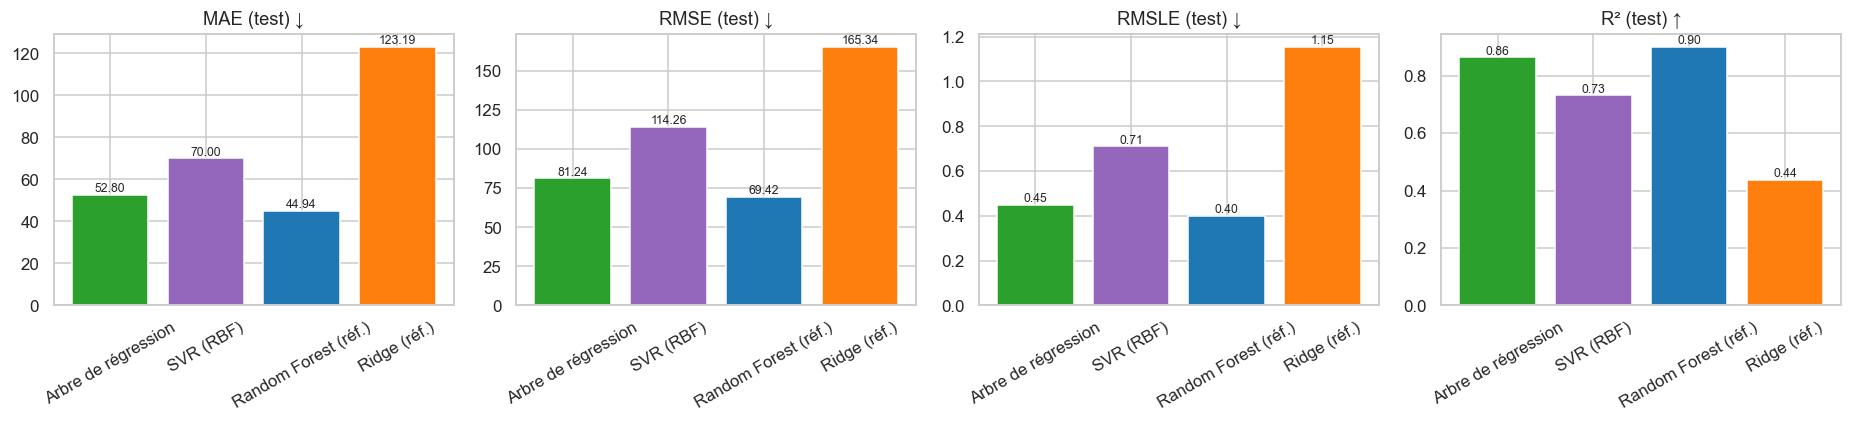

In [6]:
colors={"Arbre de régression":"tab:green","SVR (RBF)":"tab:purple","Random Forest (réf.)":"tab:blue","Ridge (réf.)":"tab:orange"}
fig,axes=plt.subplots(1,4,figsize=(17,4))
for ax,m in zip(axes,["MAE","RMSE","RMSLE","R²"]):
    v=metrics[m]; b=ax.bar(v.index,v.values,color=[colors[k] for k in v.index])
    ax.set_title(f"{m} (test) "+("↑" if m=="R²" else "↓")); ax.tick_params(axis="x",rotation=30)
    for r,x in zip(b,v.values): ax.text(r.get_x()+r.get_width()/2,r.get_height(),f"{x:.2f}",ha="center",va="bottom",fontsize=8)
save_show("07_comparaison_metriques_dt_svr")

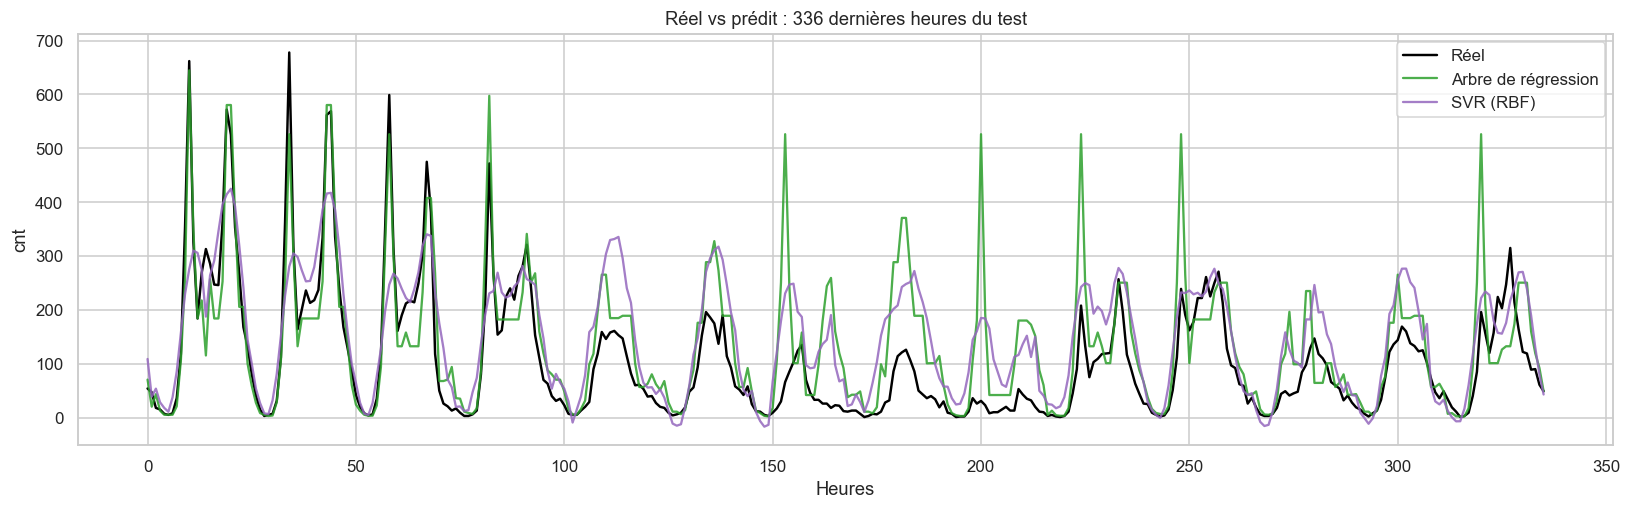

In [7]:
k=336; idx=np.arange(k)
fig,ax=plt.subplots(figsize=(15,4.8))
ax.plot(idx,y_test.values[-k:],color="black",lw=1.6,label="Réel")
for name in ["Arbre de régression","SVR (RBF)"]:
    ax.plot(idx,preds[name][-k:],color=colors[name],alpha=.85,label=name)
ax.set(title="Réel vs prédit : 336 dernières heures du test",xlabel="Heures",ylabel="cnt"); ax.legend()
save_show("08_serie_temporelle_dt_svr")

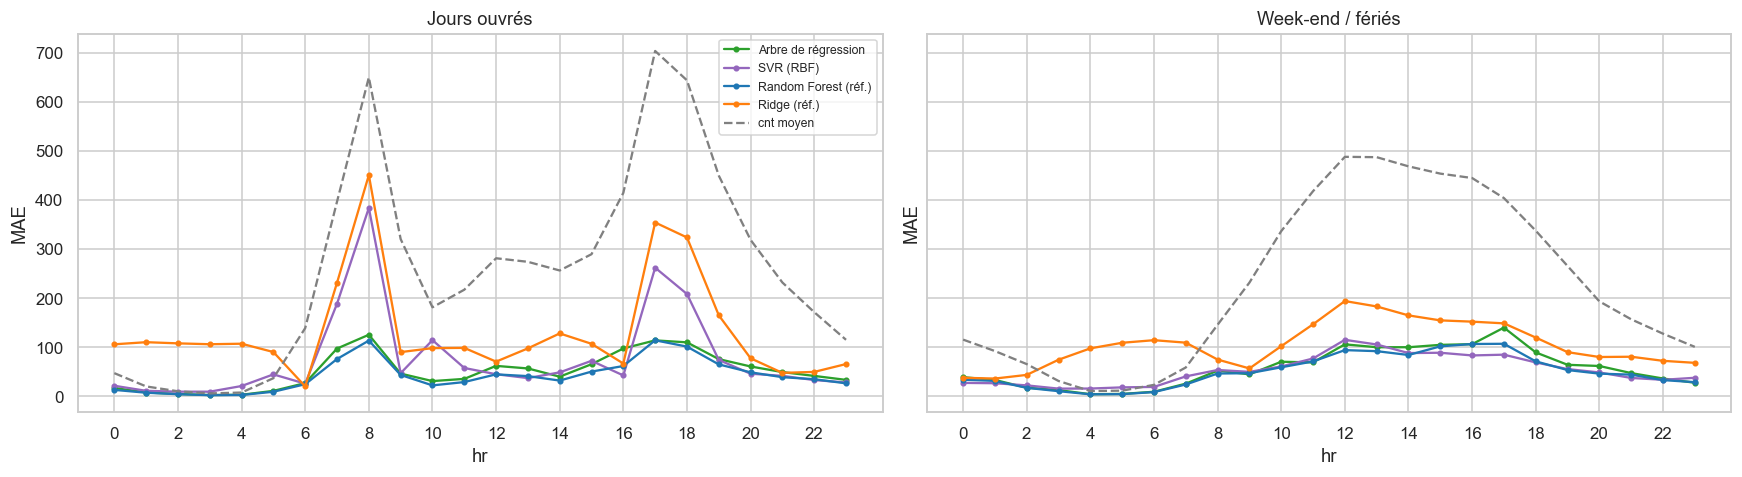

,Arbre de régression,SVR (RBF),Random Forest (réf.),Ridge (réf.)
hr,,,,
Nuit 0-5h,20.9,27.0,19.2,99.5
Pointe matin 6-9h,92.4,190.0,80.9,230.5
Journée 10-15h,82.9,87.6,71.3,137.4
Pointe soir 16-19h,128.6,165.0,108.7,248.1
Soirée 20-23h,58.8,48.6,47.7,77.8


In [8]:
err=pd.DataFrame({"hr":X_test["hr"].values,"workingday":X_test["workingday"].values,"cnt":y_test.values})
for k,p in preds.items(): err[k]=np.abs(y_test.values-p)
fig,axes=plt.subplots(1,2,figsize=(16,4.5),sharey=True)
for ax,(wk,t) in zip(axes,[(1,"Jours ouvrés"),(0,"Week-end / fériés")]):
    g=err[err.workingday==wk].groupby("hr")[list(models)+["cnt"]].mean()
    for k in models: ax.plot(g.index,g[k],marker="o",ms=3,color=colors[k],label=k)
    ax.plot(g.index,g["cnt"],"--",color="gray",label="cnt moyen"); ax.set(title=t,xlabel="hr",ylabel="MAE"); ax.set_xticks(range(0,24,2))
axes[0].legend(fontsize=8); save_show("09_erreur_par_heure_dt_svr")

tranches=pd.cut(err.hr,[-1,5,9,15,19,23],labels=["Nuit 0-5h","Pointe matin 6-9h","Journée 10-15h","Pointe soir 16-19h","Soirée 20-23h"])
rmse_tr=pd.DataFrame({k:err.groupby(tranches)[k].apply(lambda s:np.sqrt((s**2).mean())) for k in models})
display(rmse_tr.round(1))

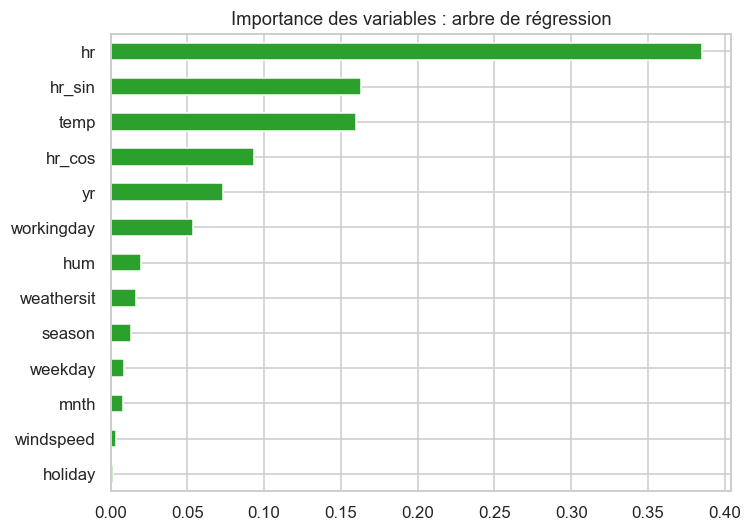

In [9]:
imp=pd.Series(models["Arbre de régression"].feature_importances_,index=X.columns).sort_values()
imp.plot(kind="barh",color=colors["Arbre de régression"],figsize=(7,5),title="Importance des variables : arbre de régression")
save_show("10_importance_arbre")

## 5. Lecture des résultats (à compléter avec vos chiffres)

- **Arbre de régression** : capte bien le profil horaire (`hr` domine l'importance) mais reste moins précis qu'une forêt : un arbre unique a une variance élevée.
- **SVR** : sensible à l'échelle et au choix de `C` / `gamma`. Il lisse davantage les pointes, donc sous-estime les heures de pointe ; le coût de calcul croît vite avec le nombre de lignes.
- **Heures de pointe** (8h et 17-18h en jours ouvrés) : là où l'erreur absolue est la plus forte pour tous les modèles.
- **Limites** : météo observée et non prévue en production ; demande moyenne plus élevée dans le test que dans le train (dérive), que les arbres ne savent pas extrapoler.

6.Sauvegarde

In [10]:
import joblib, json
from pathlib import Path

MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)

# Pipelines complets (préparation + modèle) : on les recharge et on appelle .predict()
joblib.dump(gs_dt.best_estimator_,  MODELS_DIR / "decision_tree.joblib",  compress=3)
joblib.dump(gs_svr.best_estimator_, MODELS_DIR / "svr_pipeline.joblib",   compress=3)

# Métriques et paramètres pour garder une trace
meta = {
    "split": "chronologique 80/20",
    "input_columns": list(X_train.columns),
    "decision_tree_params": gs_dt.best_params_,
    "svr_params": gs_svr.best_params_,
    "metrics_test": metrics.loc[["Arbre de régression", "SVR (RBF)"]].round(4).to_dict(orient="index"),
}
(MODELS_DIR / "metadata_dt_svr.json").write_text(
    json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

# Contrôle : le rechargement doit donner exactement les mêmes prédictions
dt_loaded  = joblib.load(MODELS_DIR / "decision_tree.joblib")
svr_loaded = joblib.load(MODELS_DIR / "svr_pipeline.joblib")
assert np.allclose(dt_loaded.predict(X_test),  preds["Arbre de régression"])
assert np.allclose(svr_loaded.predict(X_test), preds["SVR (RBF)"])
print("Sauvegarde et rechargement OK")

Sauvegarde et rechargement OK


7. Test


In [11]:
import joblib, numpy as np, pandas as pd

dt  = joblib.load("models/decision_tree.joblib")
svr = joblib.load("models/svr_pipeline.joblib")

# Une heure à prédire : jour ouvré, 8h du matin, été, temps clair
hr = 8
nouvelle_heure = pd.DataFrame([{
    "season": 3, "yr": 1, "mnth": 7, "hr": hr,
    "holiday": 0, "weekday": 2, "workingday": 1,
    "weathersit": 1, "temp": 0.70, "hum": 0.50, "windspeed": 0.15,
    "hr_sin": np.sin(2 * np.pi * hr / 24), "hr_cos": np.cos(2 * np.pi * hr / 24),
}])

print("Arbre :", round(float(dt.predict(nouvelle_heure)[0])), "vélos")
print("SVR   :", round(float(svr.predict(nouvelle_heure)[0])), "vélos")

# Test sur plusieurs heures : profil d'une journée ouvrée type
journee = pd.concat([nouvelle_heure.assign(hr=h,
                     hr_sin=np.sin(2*np.pi*h/24), hr_cos=np.cos(2*np.pi*h/24))
                     for h in range(24)], ignore_index=True)
resultat = pd.DataFrame({"hr": range(24),
                         "arbre": dt.predict(journee).round(),
                         "svr":   svr.predict(journee).round()})
print(resultat.to_string(index=False))

Arbre : 683 vélos
SVR   : 301 vélos
 hr  arbre   svr
  0   51.0  78.0
  1   17.0  27.0
  2   11.0   0.0
  3    8.0  -1.0
  4    8.0  28.0
  5   35.0  85.0
  6  163.0 162.0
  7  489.0 241.0
  8  683.0 301.0
  9  327.0 330.0
 10  185.0 329.0
 11  217.0 312.0
 12  257.0 299.0
 13  257.0 311.0
 14  257.0 360.0
 15  257.0 442.0
 16  438.0 534.0
 17  822.0 605.0
 18  822.0 627.0
 19  618.0 588.0
 20  438.0 496.0
 21  306.0 376.0
 22  216.0 255.0
 23  151.0 154.0
